# RBC OB 대조 — NOB 윗벽(차가운 벽) 속도 rms 스파이크가 상수물성에서 사라지는가 (2026-10-13/14)

질문: `rbc_nob`(글리세롤 ΔT 40 K, Ra 1e6, Pr 2547, 128×128×256, γ_z 2.6, CFL 0.3)의 윗벽 근처 속도 rms 스파이크가 NOB 경로의 문제인지 —
**물성만 상수(OB)로 바꾼 같은 조건**에서 윗벽·아랫벽 근처 u_h·w·T rms 를 비교한다. 설계 문서 `docs/Design/20261013_rbc_ob_constant_property_control.md`.

케이스 (전부 같은 격자·Ra·Pr·CFL 0.3·dt_max 0.05·냉시작·통계 16900 부터; NOB 는 ΔT 40 K):
- **NOB** `stats_nob_dt40` (냉시작 창 16900~25000, w_rms 만) · `stats_nob_dt40_base` (25300~27000 확장통계, CFL dt → 스파이크) · `stats_nob_dt40_visc12` (dt 제한 D_× 12, 스파이크 없음)
- **가변물성 경로 ΔT=0** (`rbc_nob` 앱, 모든 물성 ≡ 1 — NOB 와 같은 커널·같은 블록 커플링·같은 압력 예측자; 물성만 상수) `stats_nob_ob_limit_cold` + 스파이크 상태 재시작 `stats_nob_ob_limit_restart`
- **상수물성 커널** (`rbc_ob` 앱 신설: DHVC 가 쓰는 `*_constant_property` 충실 커널 + 증분 투영) `stats_ob_pr2547_z256`
- 참고 **legacy `rbc` 앱**(간이 OB 스킴, `equation/momentum/legacy_ob` — "운동량이 dt 에 비례해 샘, 쓰지 말 것") `stats_rbc_ob_pr2547_z256`: Pr 2547·dt 0.05 에서 벽이 미끄럼처럼 거동(벽 인접 u_rms 12×, w_rms ∝ z, Nu 14 vs 9.9)

파일 형식: NOB 식 `rbc_nob_stats_*.dat` (z T_mean u_rms v_rms w_rms T_rms wT_mean Nu_z κ̂ μ̂ ke; w 행 k = 셀 k 아래 면), legacy rbc 는 `rbc_stats_*.dat` (z T_mean w_rms wT_mean T_rms u_rms v_rms).


In [1]:
"""NOB 윗벽 rms 스파이크의 OB 대조 — 벽 인접 rms 프로파일(아랫벽 vs 윗벽)과 모니터 max|U| 비교 (2026-10-13)."""
import glob, os, re, sys
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))  # apps/
OUT = sys.argv[1] if len(sys.argv) > 1 else "/tmp/claude-20027/-shared-home-wel1come1234-workspace/61eb6613-eba5-4eb2-ba28-4fd42cd8ba3c/scratchpad"
CASES = [  # (label, stats glob, monitor log glob, kind)
    ("NOB dT40 cold 16900-25000 (CFL dt, spike)",   f"{ROOT}/rbc_nob/stats_nob_dt40/rbc_nob_stats_*.dat",          f"{ROOT}/rbc_nob/log/rbc_nob_dt40_gpu02_35486.log", "nob_basic"),
    ("NOB dT40 base 25300-27000 (CFL dt, spike)",   f"{ROOT}/rbc_nob/stats_nob_dt40_base/rbc_nob_stats_*.dat",     f"{ROOT}/rbc_nob/log/dt40_base_35985.log", "nob"),
    ("NOB dT40 visc12 25300-26500 (D_x 12)",        f"{ROOT}/rbc_nob/stats_nob_dt40_visc12/rbc_nob_stats_*.dat",   f"{ROOT}/rbc_nob/log/dt40_visc12_35989.log", "nob"),
    ("var-path dT=0 cold 16900-27000 (same kernels)", f"{ROOT}/rbc_nob/stats_nob_ob_limit_cold/rbc_nob_stats_*.dat", f"{ROOT}/rbc_nob/log/oblim_cold_full_*.log", "nob"),
    ("rbc_ob const kernels cold 16900-27000",       f"{ROOT}/rbc_ob/stats_ob_pr2547_z256/rbc_nob_stats_*.dat",     f"{ROOT}/rbc_ob/log/ob_cold_36041.log", "ob_faithful"),
    ("var-path dT=0 restart 25100-25600",           f"{ROOT}/rbc_nob/stats_nob_ob_limit_restart/rbc_nob_stats_*.dat", f"{ROOT}/rbc_nob/log/ob_control_oblim_restart_[0-9]*.log", "nob"),
    ("legacy rbc app cold 16900-27000 (slip)",   f"{ROOT}/rbc/stats_rbc_ob_pr2547_z256/rbc_stats_*.dat",        f"{ROOT}/rbc/log/ob_cold_36040.log", "ob"),
]

def header_meta(path):
    meta = {}
    for l in open(path):
        if not l.startswith("#"): break
        meta.update({k: v for k, v in re.findall(r"(\w+)=([-\d.eE+]+)", l)})
    return meta

def read_stats(path, kind, files=None):
    meta = header_meta(path)
    d = np.loadtxt(path, comments="#")
    nan = np.full(d.shape[0], np.nan)
    if kind in ("nob", "ob_faithful"):  # z T_mean u_rms v_rms w_rms T_rms wT_mean Nu_z kappa mu ke
        z, u, v, w, trms, tm = d[:,0], d[:,2], d[:,3], d[:,4], d[:,5], d[:,1]
    elif kind == "nob_basic":  # z T_mean w_rms wT_mean
        z, tm, w = d[:,0], d[:,1], d[:,2]; u = v = trms = nan
    elif kind == "ob":         # z T_mean w_rms wT_mean T_rms u_rms v_rms (cumulative since stats_start)
        z, tm, w, trms, u, v = d[:,0], d[:,1], d[:,2], d[:,4], d[:,5], d[:,6]
    elif kind == "ob_window":  # last file minus the file closest to t=25900: sums = mean*samples (rms -> mean square)
        early = min(files, key=lambda f: abs(float(header_meta(f)["t"]) - 25900.0))
        d0 = np.loadtxt(early, comments="#"); m0 = header_meta(early)
        n1, n0 = float(meta["samples"]), float(m0["samples"]); dn = n1 - n0
        meta["t_window_start"] = m0["t"]; meta["samples_window"] = str(int(dn))
        def diff_mean(col): return (d[:,col]*n1 - d0[:,col]*n0) / dn
        def diff_rms(col):  return np.sqrt(np.maximum(0, (d[:,col]**2*n1 - d0[:,col]**2*n0) / dn))
        tm = diff_mean(1); w = diff_rms(2); u = diff_rms(5); v = diff_rms(6)
        # T_rms: file stores sqrt(<T^2>-Tm^2) -> <T^2> = rms^2 + Tm^2 per file
        t2 = ((d[:,4]**2 + d[:,1]**2)*n1 - (d0[:,4]**2 + d0[:,1]**2)*n0) / dn
        trms = np.sqrt(np.maximum(0, t2 - tm*tm)); z = d[:,0]
    else:
        raise ValueError(kind)
    return dict(z=z, uh=np.sqrt(u*u+v*v), w=w, trms=trms, tmean=tm, meta=meta)

def read_monitor(pattern, kind):
    files = sorted(glob.glob(pattern), key=os.path.getmtime)
    if not files or kind is None: return None
    rows = []
    for l in open(files[-1]):
        if not re.match(r"^\s*\d+\s", l): continue
        v = l.split()
        if kind == "nob" and len(v) == 14: rows.append([float(x) for x in v])
        if kind == "ob_faithful" and len(v) == 13: rows.append([float(x) for x in v])
        if kind == "ob" and len(v) == 9: rows.append([float(x) for x in v])
    if not rows: return None
    d = np.array(rows)
    if kind == "nob": return dict(t=d[:,1], dt=d[:,2], ubot=d[:,11], utop=d[:,12], nu=d[:,5], dx=d[:,10])
    if kind == "ob_faithful": return dict(t=d[:,1], dt=d[:,2], ubot=d[:,10], utop=d[:,11], nu=d[:,5], dx=None)
    return dict(t=d[:,1], dt=d[:,2], ubot=d[:,7], utop=d[:,8], nu=d[:,5], dx=None)

runs = []
for label, sg, mg, kind in CASES:
    files = sorted(glob.glob(sg))
    if not files: print(f"[{label}] 통계 없음"); continue
    st = read_stats(files[-1], kind, files); st["label"] = label; st["kind"] = kind; st["file"] = files[-1]
    st["mon"] = read_monitor(mg, kind if kind in ("nob", "ob", "ob_faithful") else None)
    runs.append(st)
    m = st["meta"]
    print(f"[{label}] {os.path.basename(files[-1])}  t={m.get('t')}  sum_dt/samples={m.get('sum_dt', m.get('samples'))}  window_samples={m.get('samples_window','-')}  Nu={m.get('Nu_volume')} theta_c={m.get('theta_c')}")



[NOB dT40 cold 16900-25000 (CFL dt, spike)] rbc_nob_stats_02005764.dat  t=25000.0094  sum_dt/samples=649634  window_samples=-  Nu=9.4986 theta_c=0.13518
[NOB dT40 base 25300-27000 (CFL dt, spike)] rbc_nob_stats_02166161.dat  t=27000.0035  sum_dt/samples=1699.9989  window_samples=-  Nu=9.5106 theta_c=0.13329
[NOB dT40 visc12 25300-26500 (D_x 12)] rbc_nob_stats_02417866.dat  t=26500.0035  sum_dt/samples=1200.0011  window_samples=-  Nu=9.5139 theta_c=0.13333
[var-path dT=0 cold 16900-27000 (same kernels)] rbc_nob_stats_00541177.dat  t=27000.0319  sum_dt/samples=10099.9500  window_samples=-  Nu=9.9783 theta_c=0.00911
[rbc_ob const kernels cold 16900-27000] rbc_nob_stats_00541175.dat  t=27000.0431  sum_dt/samples=10100.0500  window_samples=-  Nu=9.8779 theta_c=0.00565
[var-path dT=0 restart 25100-25600] rbc_nob_stats_02017896.dat  t=25600.0262  sum_dt/samples=499.9997  window_samples=-  Nu=10.0054 theta_c=0.10792
[legacy rbc app cold 16900-27000 (slip)] rbc_stats_00541352.dat  t=27000.0296 

## 1. 벽 인접 rms 표 — 아랫벽 k번째 셀 vs 윗벽 k번째 셀

NOB CFL 런은 윗/아랫 비가 u_h 305·w 642(첫 셀/면); 가변경로 ΔT=0 과 rbc_ob 는 전 k 에서 1.00 — 스파이크는 **가변 μ̂ 가 있을 때만** 생긴다.

In [2]:
KS = [1, 2, 3, 5, 8, 16]
print("\n== 벽 인접 rms: 아랫벽 k번째 셀 / 윗벽 k번째 셀 (k=1 이 벽 인접). w_rms 는 셀 아래 면(k=1 → 첫 내부 면)")
for st in runs:
    nz = len(st["z"]); print(f"-- {st['label']}")
    for name, arr in (("u_h,rms", st["uh"]), ("w_rms", st["w"]), ("T_rms", st["trms"])):
        bot = [arr[k] if name == "w_rms" else arr[k-1] for k in KS]
        top = [arr[nz-k] if name == "w_rms" else arr[nz-k] for k in KS]   # w face above cell nz-k = face index nz-k+1? faces: row k = face below cell k; top wall face is ghost → use face below cell nz-k+1 = row nz-k+1
        # w 행 k = 셀 k 아래 면: 아랫벽 k번째 내부 면 = 행 k, 윗벽 k번째 내부 면 = 행 nz−k (윗벽 면은 ghost 슬롯이라 저장 안 됨)
        if name == "w_rms": top = [arr[nz-k] for k in KS]
        if np.all(np.isnan(bot)): continue
        ratio = [t/b if b > 0 else float('nan') for b, t in zip(bot, top)]
        print(f"   {name:8s} bottom " + " ".join(f"{b:9.2e}" for b in bot) + " | top " + " ".join(f"{t:9.2e}" for t in top) + " | top/bot " + " ".join(f"{r:7.1f}" for r in ratio))
    mon = st["mon"]
    if mon is not None:
        n = len(mon["t"]); q = max(1, n//4)
        print(f"   monitor: u_top_max first/quarter/half/last {mon['utop'][0]:.2e}/{mon['utop'][q]:.2e}/{mon['utop'][2*q]:.2e}/{mon['utop'][-1]:.2e}  u_bot_max last {mon['ubot'][-1]:.2e}  dt last {mon['dt'][-1]:.4f}" + (f"  D_x last {mon['dx'][-1]:.1f}" if mon['dx'] is not None else ""))




== 벽 인접 rms: 아랫벽 k번째 셀 / 윗벽 k번째 셀 (k=1 이 벽 인접). w_rms 는 셀 아래 면(k=1 → 첫 내부 면)
-- NOB dT40 cold 16900-25000 (CFL dt, spike)
   w_rms    bottom  5.91e-06  1.75e-05  3.47e-05  8.49e-05  1.97e-04  6.71e-04 | top  4.15e-03  4.61e-03  4.64e-03  4.37e-03  3.78e-03  2.34e-03 | top/bot   702.6   263.1   133.9    51.5    19.2     3.5
-- NOB dT40 base 25300-27000 (CFL dt, spike)
   u_h,rms  bottom  3.62e-04  7.07e-04  1.04e-03  1.65e-03  2.46e-03  3.96e-03 | top  1.10e-01  4.16e-02  2.84e-02  1.69e-02  9.51e-03  3.43e-03 | top/bot   304.9    58.9    27.4    10.2     3.9     0.9
   w_rms    bottom  5.93e-06  1.76e-05  3.48e-05  8.52e-05  1.98e-04  6.74e-04 | top  3.80e-03  4.21e-03  4.23e-03  3.97e-03  3.42e-03  2.10e-03 | top/bot   641.5   239.4   121.5    46.6    17.3     3.1
   T_rms    bottom  2.90e-03  8.75e-03  1.47e-02  2.68e-02  4.51e-02  8.47e-02 | top  2.26e-03  6.70e-03  1.11e-02  2.02e-02  3.43e-02  7.44e-02 | top/bot     0.8     0.8     0.8     0.8     0.8     0.9
   monitor: u_top_ma

## 2. 벽에서의 거리별 프로파일 (실선 아랫벽, 점선 윗벽)

무활주 벽의 점근: u_h,rms ∝ z, w_rms ∝ z². legacy rbc 는 u_h 가 평탄하고 w ∝ z (미끄럼).

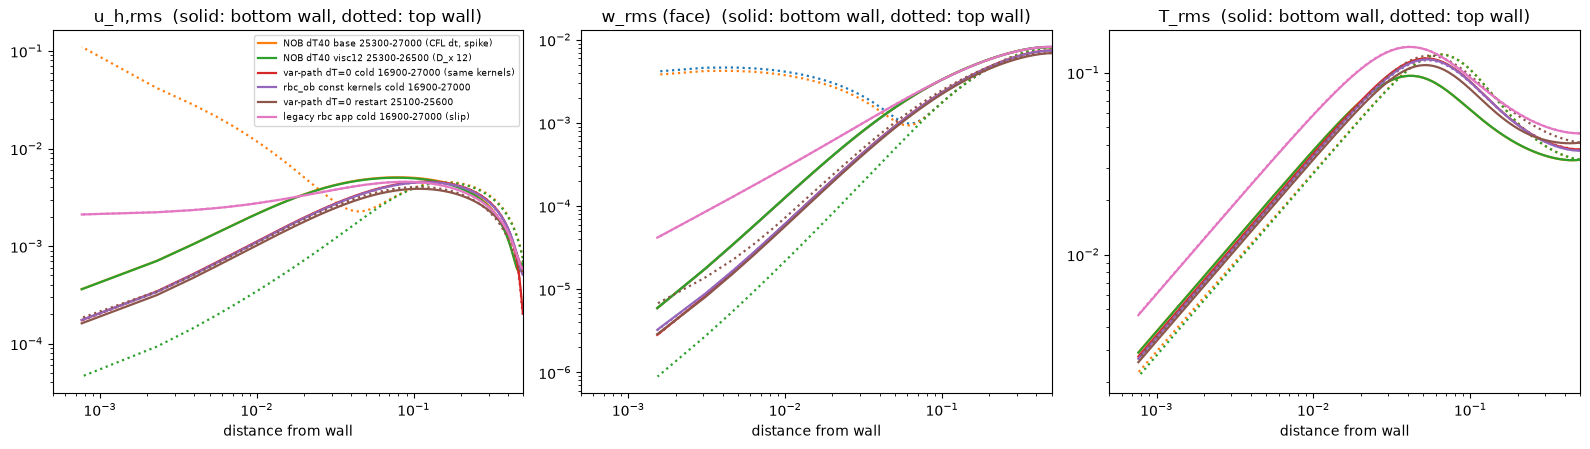

In [3]:
# 그림 1: 벽에서의 거리별 프로파일 (아랫벽 실선, 윗벽 점선)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
colors = plt.cm.tab10(np.linspace(0, 1, 10))
for i, st in enumerate(runs):
    z = st["z"]; nz = len(z); lz = 1.0
    for ax, name, arr in zip(axes, ("u_h,rms", "w_rms (face)", "T_rms"), (st["uh"], st["w"], st["trms"])):
        if np.all(np.isnan(arr)): continue
        if name.startswith("w"):
            zb = z - 0.5*np.gradient(z); zb[0] = 0  # face below cell ≈ z_face
            db, dt_ = zb, lz - zb
            ax.loglog(db[1:nz//2], arr[1:nz//2], color=colors[i], lw=1.6, label=st["label"])
            ax.loglog(dt_[nz//2:], arr[nz//2:], color=colors[i], lw=1.6, ls=":")
        else:
            ax.loglog(z[:nz//2], arr[:nz//2], color=colors[i], lw=1.6, label=st["label"])
            ax.loglog((lz - z)[nz//2:], arr[nz//2:], color=colors[i], lw=1.6, ls=":")
        ax.set_title(name + "  (solid: bottom wall, dotted: top wall)"); ax.set_xlabel("distance from wall"); ax.set_xlim(5e-4, 0.5)
axes[0].legend(fontsize=6.5)
fig.tight_layout(); plt.show()



## 3. 모니터 — 벽 인접 평면 max|U| 시간 이력 (실선 윗벽, 점선 아랫벽)

가변경로 ΔT=0 재시작은 NOB 스파이크 상태(0.46)에서 출발해 36 스텝 만에 1.8e-2, 100 time 안에 5e-4 로 붕괴한다.

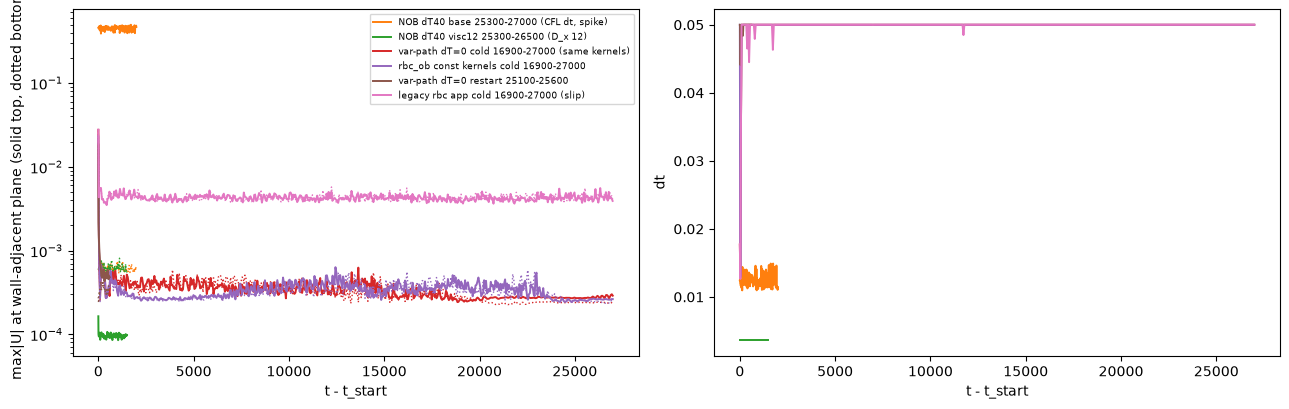

In [4]:
# 그림 2: 모니터 max|U| 윗벽/아랫벽 시간 이력
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for i, st in enumerate(runs):
    mon = st["mon"]
    if mon is None: continue
    t0 = mon["t"][0]
    axes[0].semilogy(mon["t"] - t0, mon["utop"], color=colors[i], lw=1.4, label=st["label"])
    axes[0].semilogy(mon["t"] - t0, mon["ubot"], color=colors[i], lw=1.0, ls=":")
    axes[1].plot(mon["t"] - t0, mon["dt"], color=colors[i], lw=1.4)
axes[0].set_ylabel("max|U| at wall-adjacent plane (solid top, dotted bottom)"); axes[0].set_xlabel("t - t_start"); axes[0].legend(fontsize=6.5)
axes[1].set_ylabel("dt"); axes[1].set_xlabel("t - t_start")
fig.tight_layout(); plt.show()


## 4. legacy rbc 앱의 미끄럼 거동 소형 진단 (48×48×96)

dt 를 1/10 로 줄이면 완화되고(멱지수 0.23→0.44, 벽 Nu 17→13.6) Pr 0.7(CFL 이 dt 를 0.004 로 묶음)은 무활주 — legacy 머리말의 "dt 에 비례하는 운동량 누수"가 큰 ν dt/Δz²(Pr 2547, dt 0.05: ~10³)에서 벽 미끄럼으로 나타난 것. 가변경로·rbc_ob 는 같은 dt 에서 무활주.

In [5]:
# legacy rbc 앱(간이 OB 스킴)의 소형 진단 — 48×48×96, t 200~400: 벽 인접 멱지수로 무활주/미끄럼 판정
import re
def load_small(path, kind):
    d = np.loadtxt(path, comments="#"); z = d[:,0]
    if kind == "ob": uh = np.sqrt(d[:,5]**2 + d[:,6]**2); w = d[:,2]; tm = d[:,1]
    else: uh = np.sqrt(d[:,2]**2 + d[:,3]**2); w = d[:,4]; tm = d[:,1]
    return z, uh, w, tm
def slope(zz, yy, a, b): return np.polyfit(np.log(zz[a:b]), np.log(yy[a:b]), 1)[0]
DIAG = (("legacy rbc, Pr 2547, dt_max 0.05", f"{ROOT}/rbc/stats_rbc_diag_const_pr2547/rbc_stats_*.dat", "ob", f"{ROOT}/rbc/log/diag_input_rbc_diag_const_pr2547.log"),
        ("legacy rbc, Pr 2547, dt_max 0.005", f"{ROOT}/rbc/stats_rbc_diag_const_pr2547_dt005/rbc_stats_*.dat", "ob", f"{ROOT}/rbc/log/diag_input_rbc_diag_const_pr2547_dt005.log"),
        ("legacy rbc, Pr 0.7, dt_max 0.05 (CFL-bound)", f"{ROOT}/rbc/stats_rbc_diag_const_pr07/rbc_stats_*.dat", "ob", f"{ROOT}/rbc/log/diag_input_rbc_diag_const_pr07.log"),
        ("variable path dT=0, Pr 2547, dt_max 0.05", f"{ROOT}/rbc_nob/stats_nob_diag_var_pr2547/rbc_nob_stats_*.dat", "nob", f"{ROOT}/rbc_nob/log/diag_input_rbc_nob_diag_var_pr2547.log"))
print(f"{'case':46s} {'uh exp':>7s} {'w exp':>6s} {'uh(k=1)':>9s} {'wallNu':>7s} {'Nu_vol':>7s} {'dt(last)':>8s}   (no-slip: uh ~ z^1, w ~ z^2; slip: uh flat, w ~ z)")
for label, pat, kind, log in DIAG:
    fs = sorted(glob.glob(pat))
    if not fs: print(f"{label:46s} (no stats)"); continue
    z, uh, w, tm = load_small(fs[-1], kind); zf = np.concatenate([[0], 0.5*(z[1:]+z[:-1])])
    fin = [l for l in open(log) if "FINAL" in l]; nu = re.search(r"Nu = ([\d.]+)", fin[-1]).group(1) if fin else "-"
    rows = [l.split() for l in open(log) if re.match(r"^\s*\d+\s", l)]; dt = rows[-1][2] if rows else "-"
    print(f"{label:46s} {slope(z,uh,1,6):7.2f} {slope(zf,w,1,6):6.2f} {uh[0]:9.2e} {(0.5-tm[0])/z[0]:7.2f} {nu:>7s} {dt:>8s}")


case                                            uh exp  w exp   uh(k=1)  wallNu  Nu_vol dt(last)   (no-slip: uh ~ z^1, w ~ z^2; slip: uh flat, w ~ z)
legacy rbc, Pr 2547, dt_max 0.05                  0.23   1.05  2.52e-03   17.09 16.5803  0.05000
legacy rbc, Pr 2547, dt_max 0.005                 0.44   1.32  7.05e-04   13.61  7.5659  0.00500
legacy rbc, Pr 0.7, dt_max 0.05 (CFL-bound)       0.59   1.50  4.57e-02   10.27 10.2703  0.00404
variable path dT=0, Pr 2547, dt_max 0.05          0.61   1.56  3.77e-04   12.66  6.5758  0.05000
